# Finding Missing values

In [90]:
import missingno as msno
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

df = pd.read_csv("./data/02_data_type_conversion.csv")

In [91]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 57303 entries, 0 to 57302
Data columns (total 44 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   district_name                  57303 non-null  object 
 1   block_tehsil_name              57303 non-null  object 
 2   village_name                   57303 non-null  object 
 3   latitude                       57303 non-null  float64
 4   longitude                      57303 non-null  float64
 5   s_no_of_scheme                 57303 non-null  int64  
 6   scheme_type                    57303 non-null  object 
 7   dugwell_type                   809 non-null    object 
 8   tubewell_type                  56494 non-null  object 
 9   ownership                      57303 non-null  object 
 10  khasra_number                  7568 non-null   float64
 11  location_particulars           51320 non-null  object 
 12  total_owners_holding           57303 non-null 

In [92]:
missing_summary = pd.DataFrame({
    'Data_Type': df.dtypes.astype(str),
    'Missing_Count': df.isnull().sum(),
    'Missing_Percentage': (df.isnull().mean() * 100).round(2),
    'Unique_Values': df.nunique()
})

missing_summary = (
    missing_summary[missing_summary['Missing_Count'] > 0]
    .sort_values('Missing_Percentage', ascending=False)
)

missing_summary

,Data_Type,Missing_Count,Missing_Percentage,Unique_Values
scheme_in_command_area_reason,object,57157,99.75,4
name_of_mmi_project,object,57142,99.72,24
status_reason_permanently,object,56536,98.66,7
dugwell_type,object,56494,98.59,4
status_reason_temporarily,object,51961,90.68,6
not_in_use_years,float64,51194,89.34,7
khasra_number,float64,49735,86.79,521
under_utilisation_reason,object,48757,85.09,6
finance_source2,object,23688,41.34,5
finance_source1,object,15969,27.87,5


In [93]:
numeric_cols = df.select_dtypes(include=['number']).columns.tolist()
categorical_cols = df.select_dtypes(include=['object', 'category', 'string']).columns.tolist()

## Misisng Value Visualization

In [94]:
plt.rcParams['figure.dpi'] = 120
plt.rcParams['savefig.dpi'] = 300

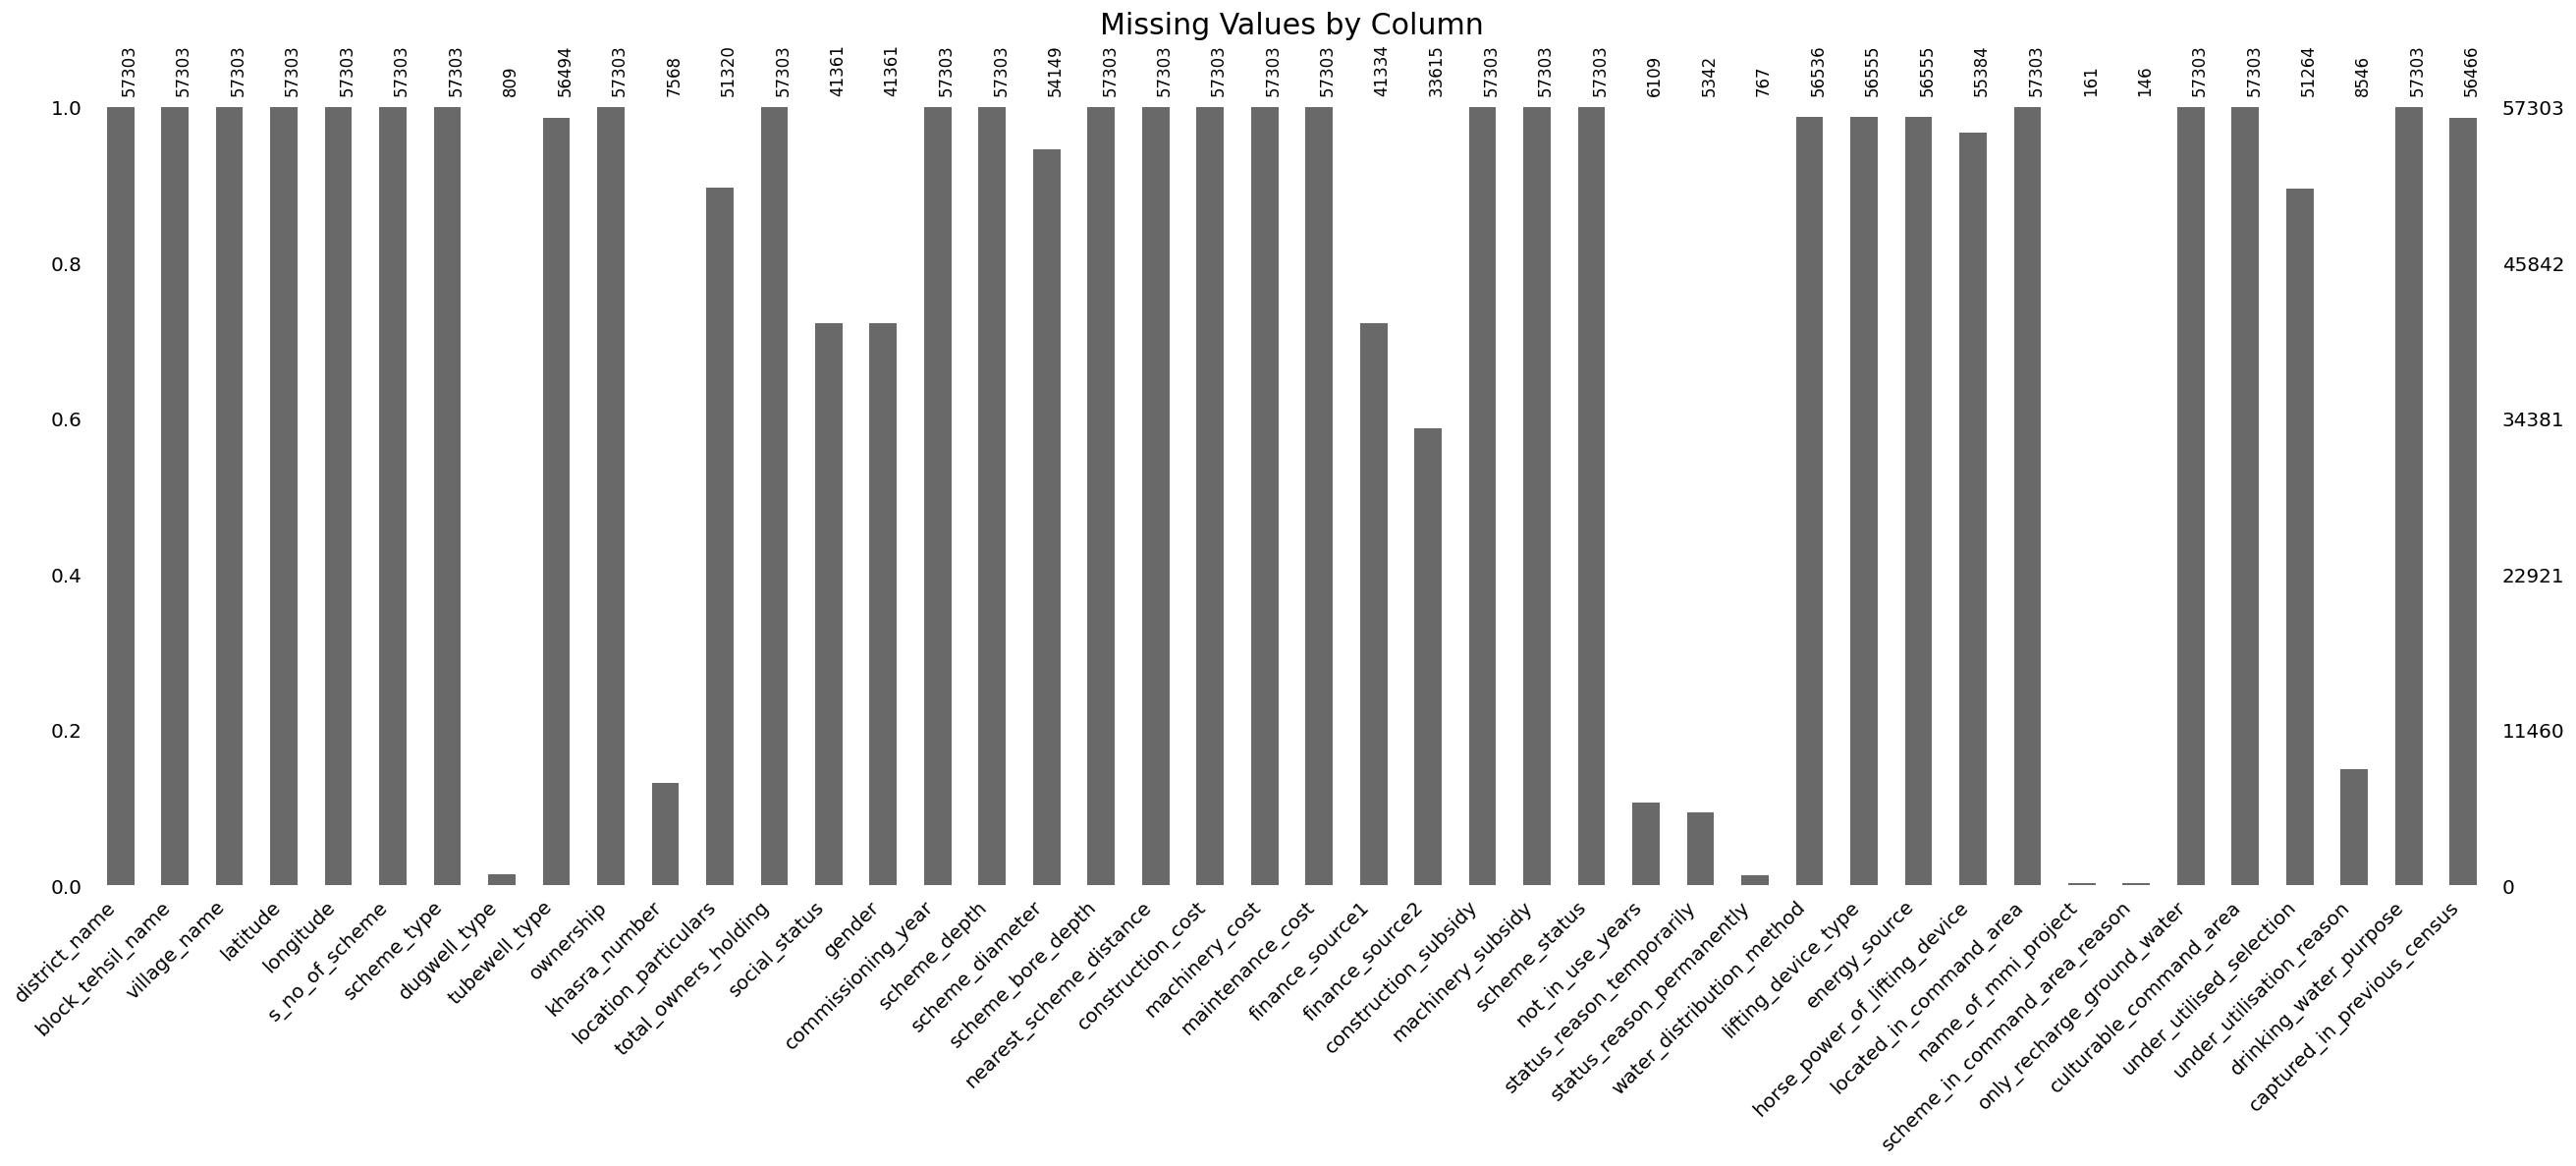

In [95]:
msno.bar(df, figsize=(22, 10), fontsize=12)
plt.title('Missing Values by Column', fontsize=18)
plt.xticks(rotation=90, fontsize=10)
plt.yticks(fontsize=12)
plt.tight_layout()
plt.show()

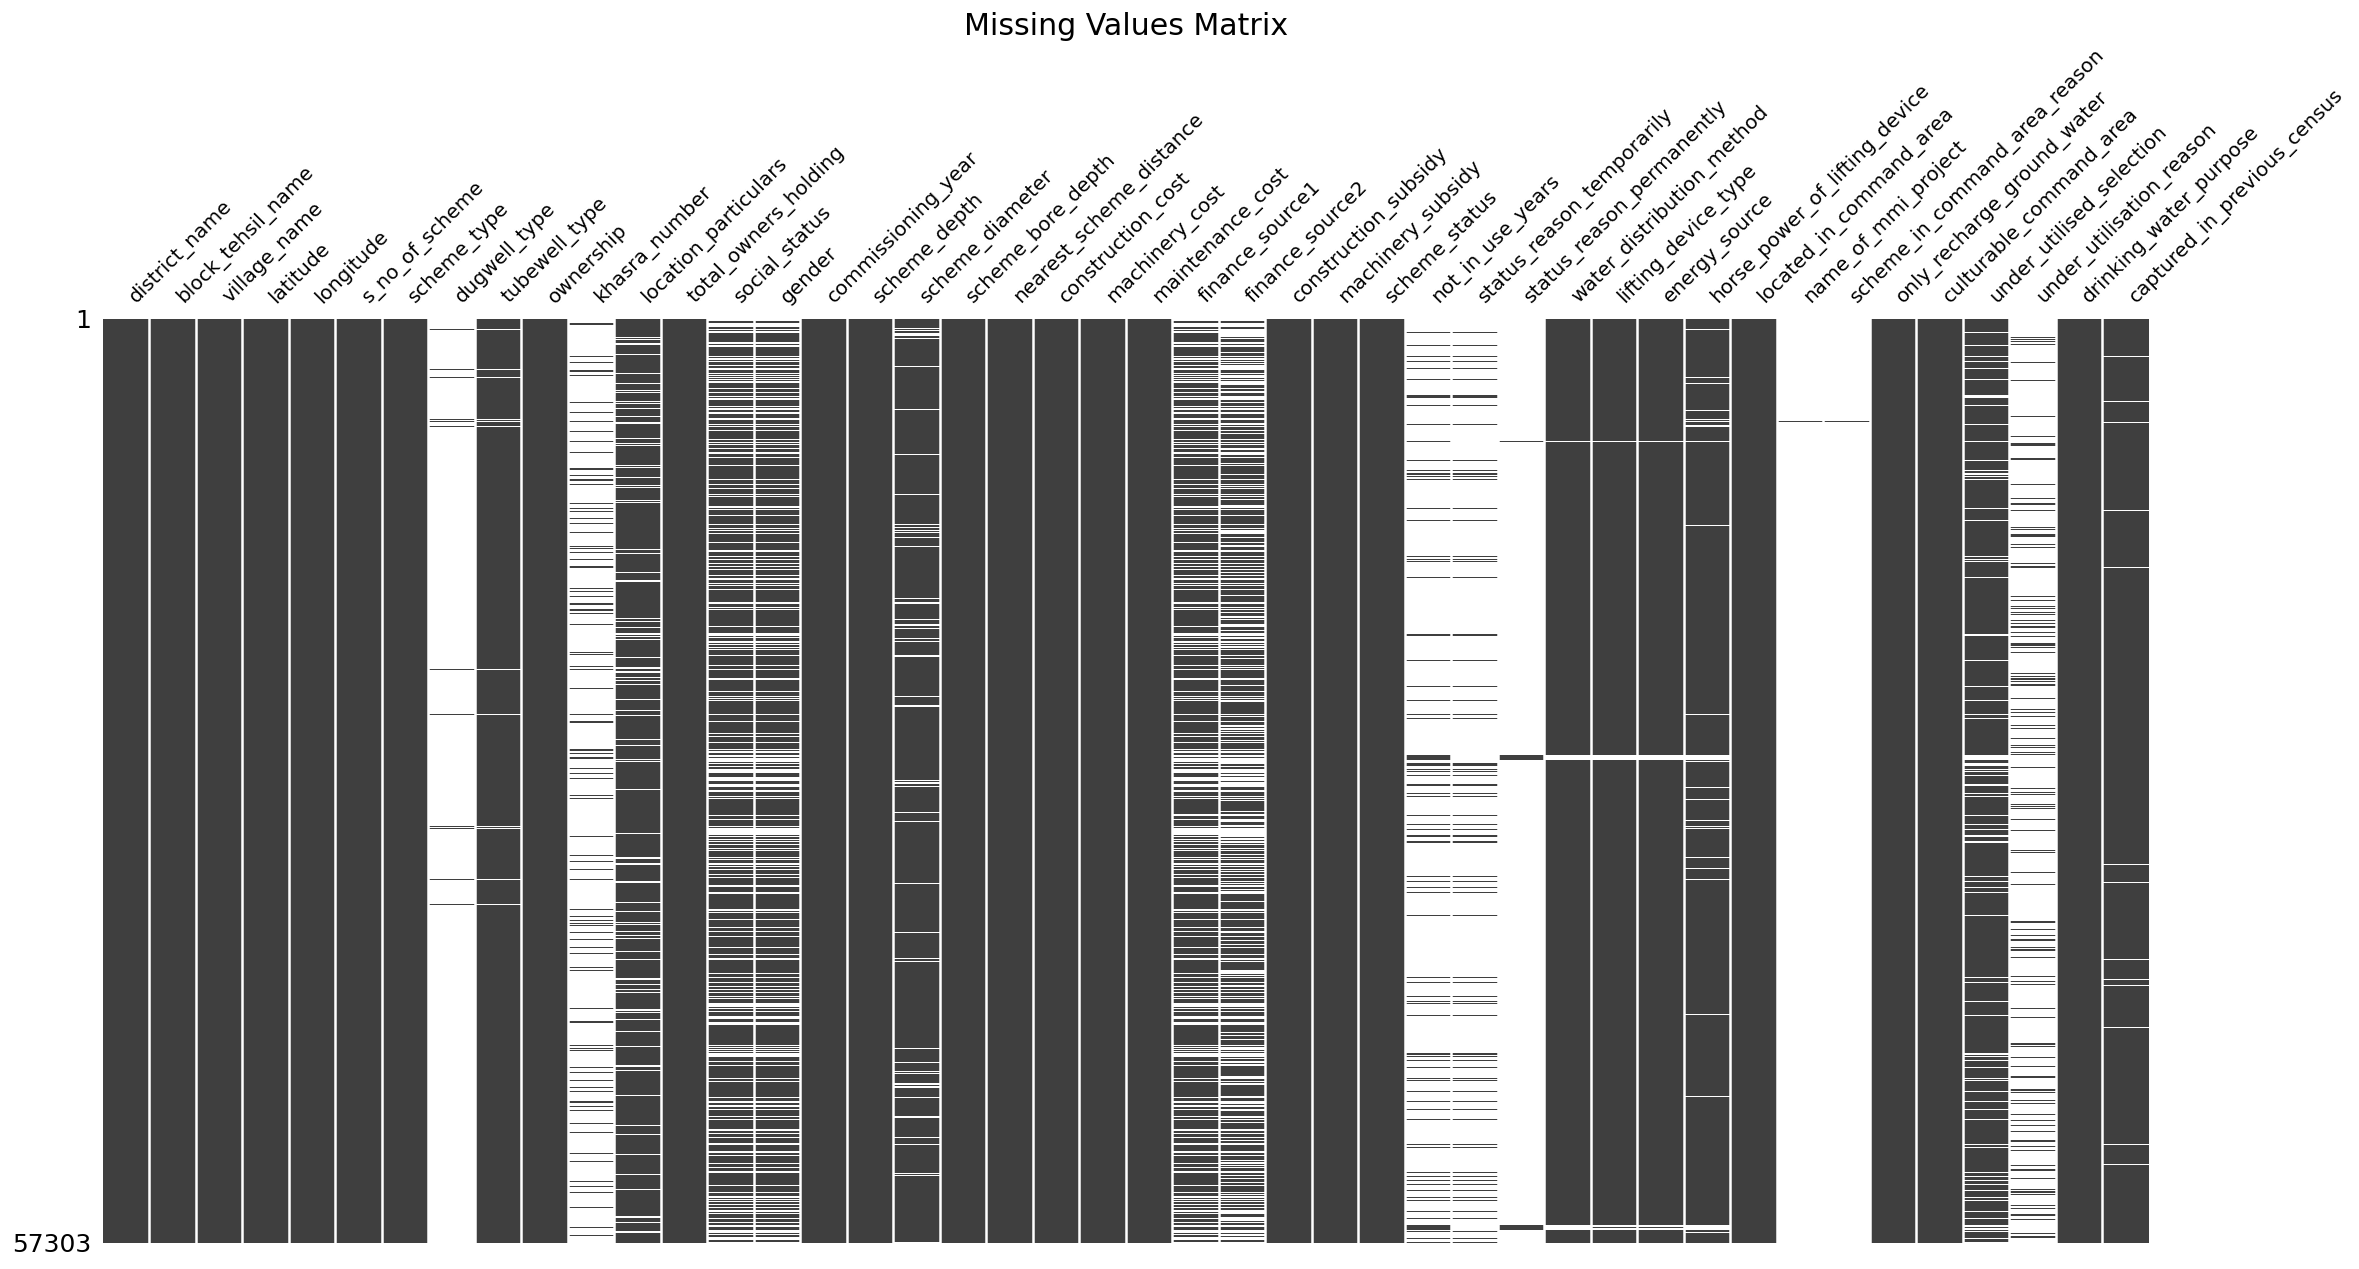

In [96]:
msno.matrix(df, figsize=(22, 10), sparkline=False, fontsize=12)
plt.title('Missing Values Matrix', fontsize=18)
plt.show()

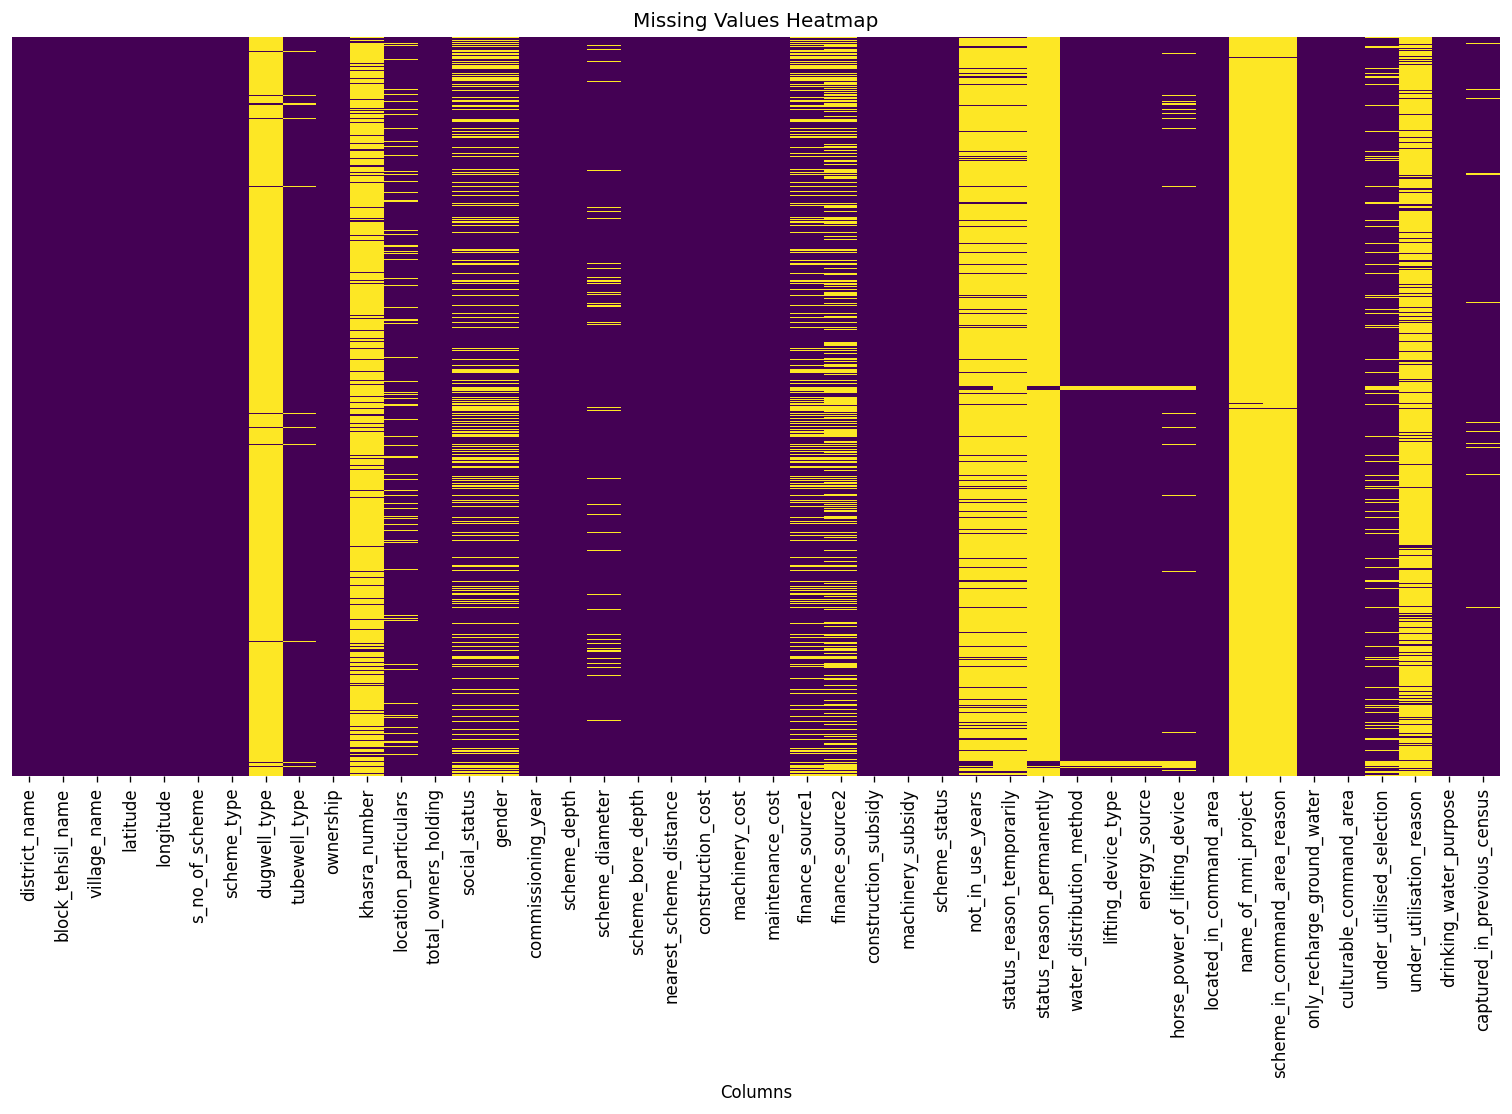

In [97]:
plt.figure(figsize=(16, 8))

sns.heatmap(
    df.isnull(),
    cbar=False,
    yticklabels=False,
    cmap='viridis'
)

plt.title('Missing Values Heatmap')
plt.xlabel('Columns')
plt.show()

In [98]:
# Dougwell type and Tube well type have relation

# not_in_use_years	status_reason_temporarily, status_reason_permanently, water_distribution_method, lifting_device_type, energy_source	
# horse_power_of_lifting_device, pump_operating_days_kharif_season, pump_operating_days_rabi_season, pump_operating_days_perennial_crop
# pump_operating_days_other_season, avg_pumping_per_day_kharif_season, avg_pumping_per_day_rabi_season, avg_pumping_per_day_perennial_crop, 
# avg_pumping_per_day_other_season are related

# there is a relation between under_utilised_selection	under_utilisation_reason

# there is a realtion between not_in_use_years	status_reason_temporarily


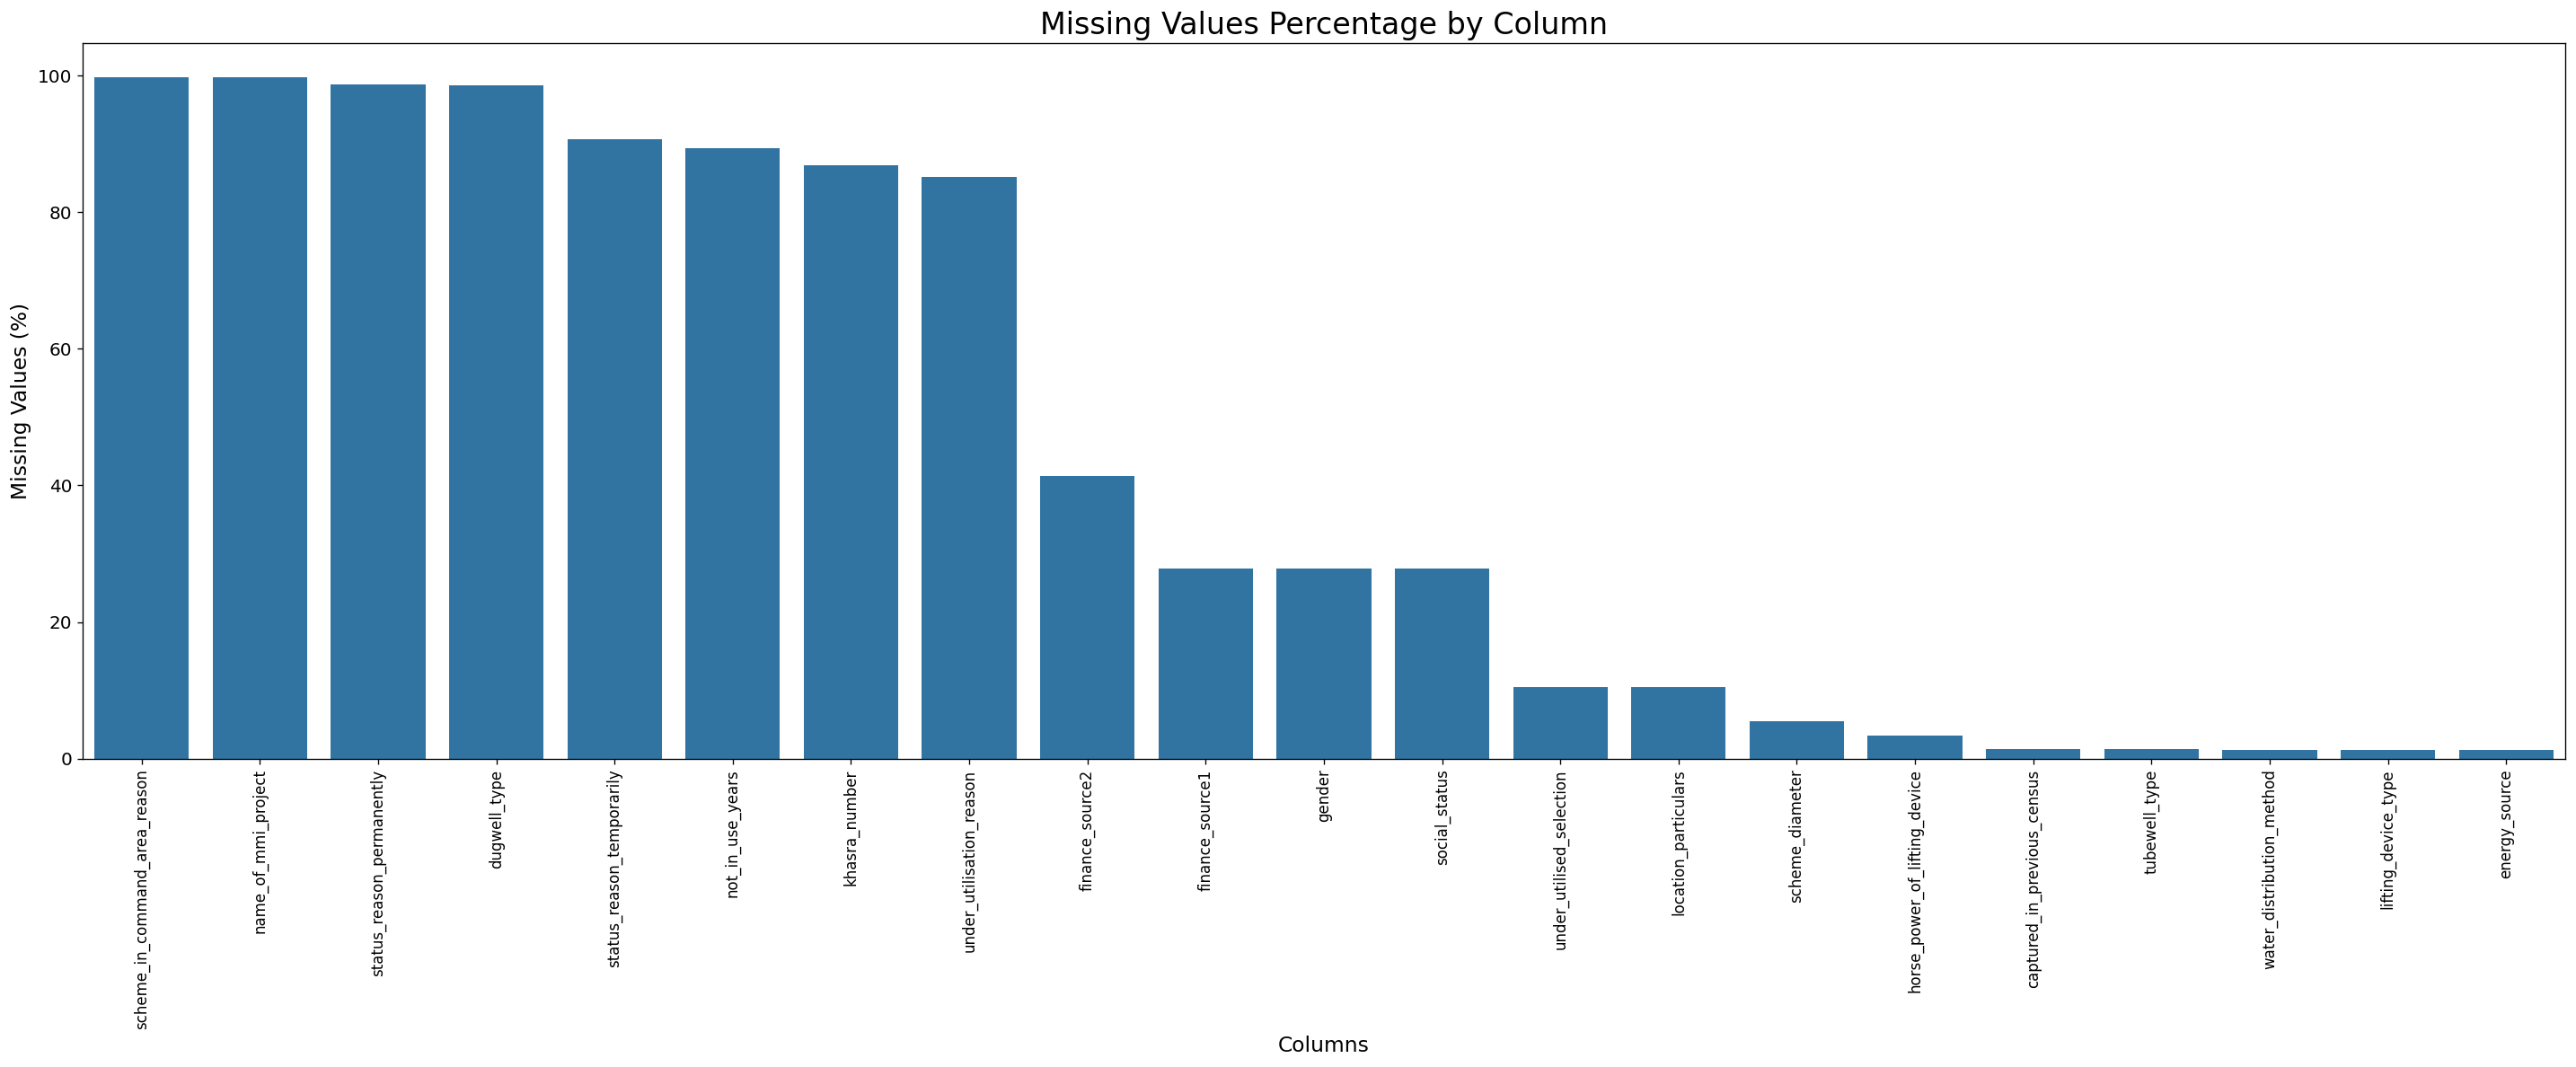

In [99]:
missing_pct = (df.isnull().mean() * 100)
missing_pct = missing_pct[missing_pct > 0].sort_values(ascending=False)

plt.figure(figsize=(24, 10))

sns.barplot(
    x=missing_pct.index,
    y=missing_pct.values
)

plt.title('Missing Values Percentage by Column', fontsize=20)
plt.xlabel('Columns', fontsize=14)
plt.ylabel('Missing Values (%)', fontsize=14)
plt.xticks(rotation=90, fontsize=10)
plt.yticks(fontsize=12)
plt.tight_layout()
plt.show()

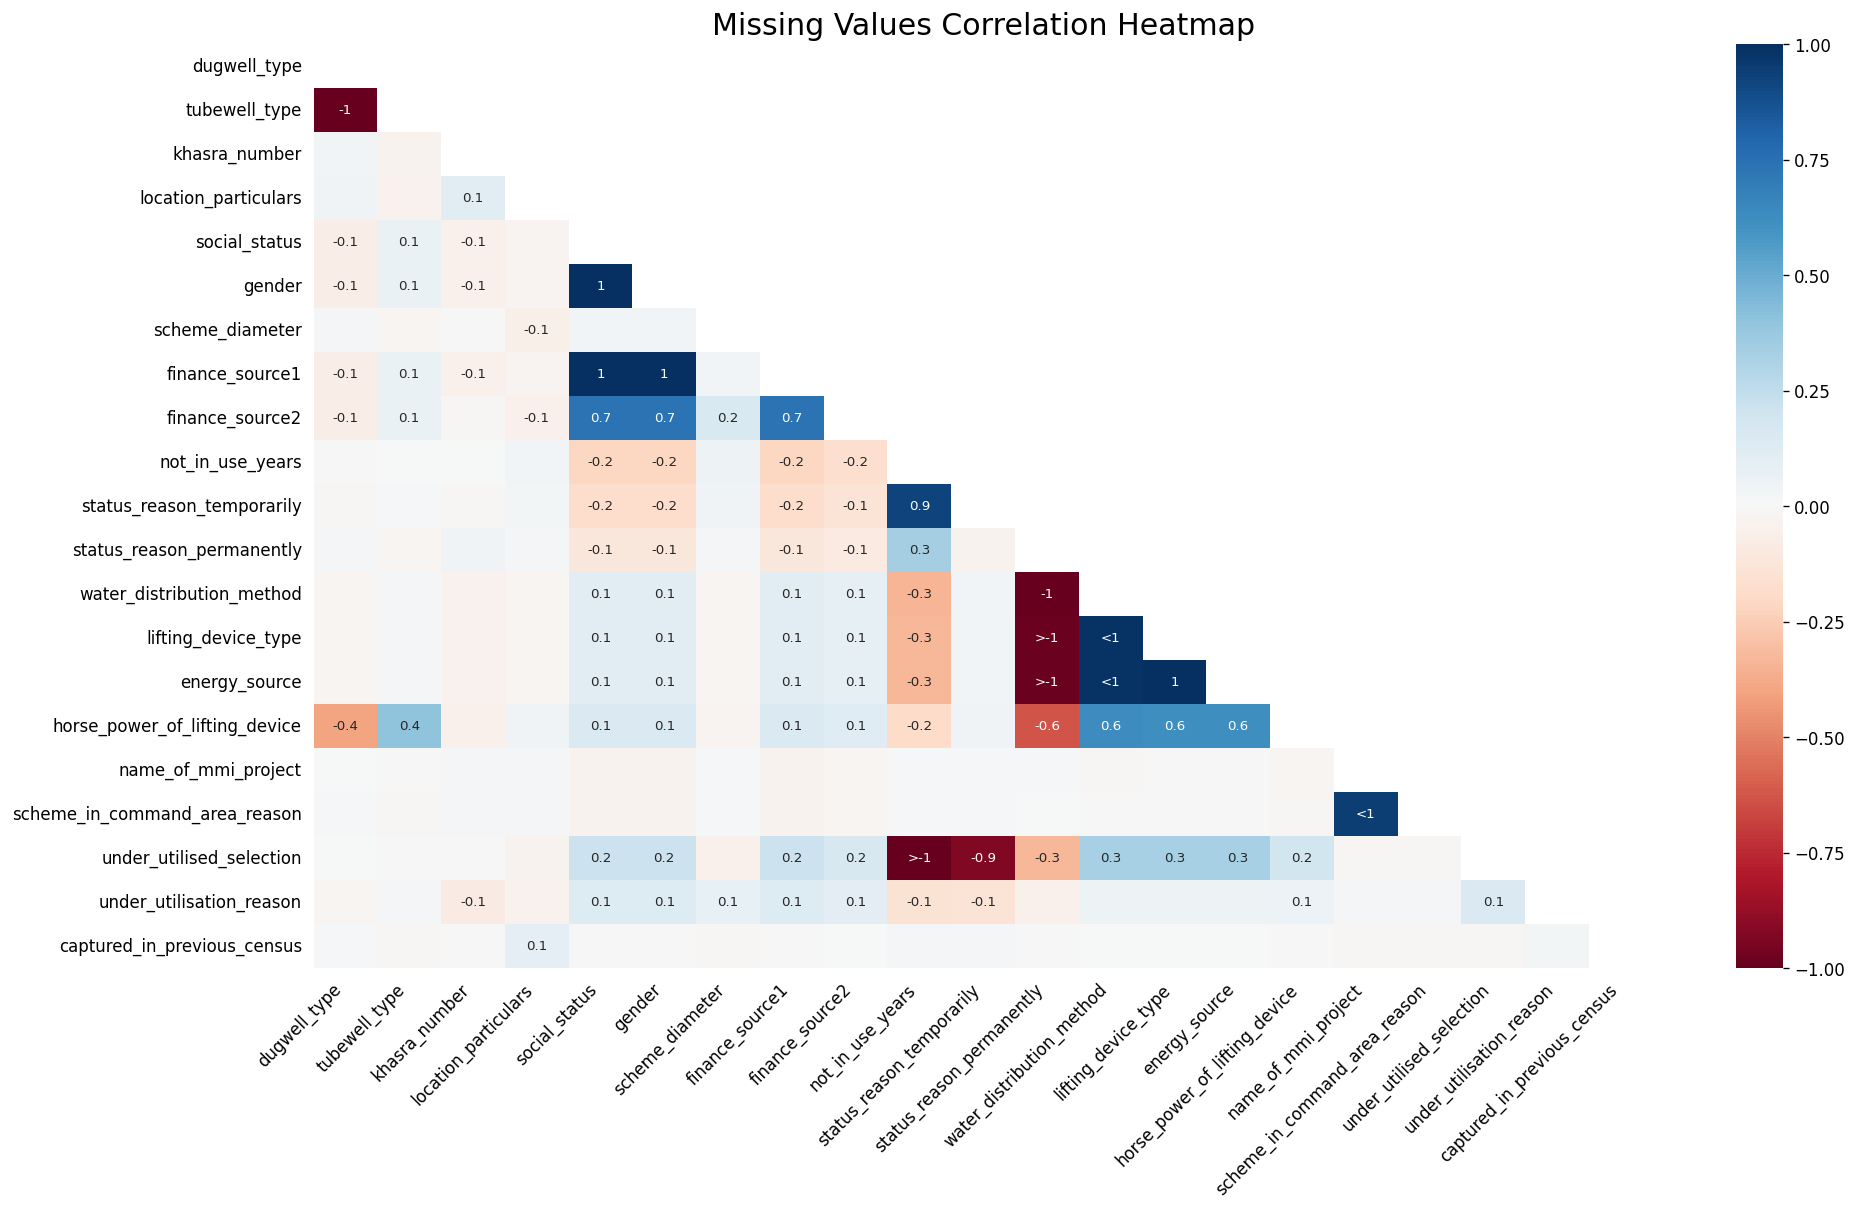

In [100]:
msno.heatmap(df, figsize=(18, 10), fontsize=10)
plt.title('Missing Values Correlation Heatmap', fontsize=18)
plt.show()

In [101]:
# there apears to be a relation between finance sorce and social status and gender
# status reason and not un use years have relation 

<Figure size 4500x2100 with 0 Axes>

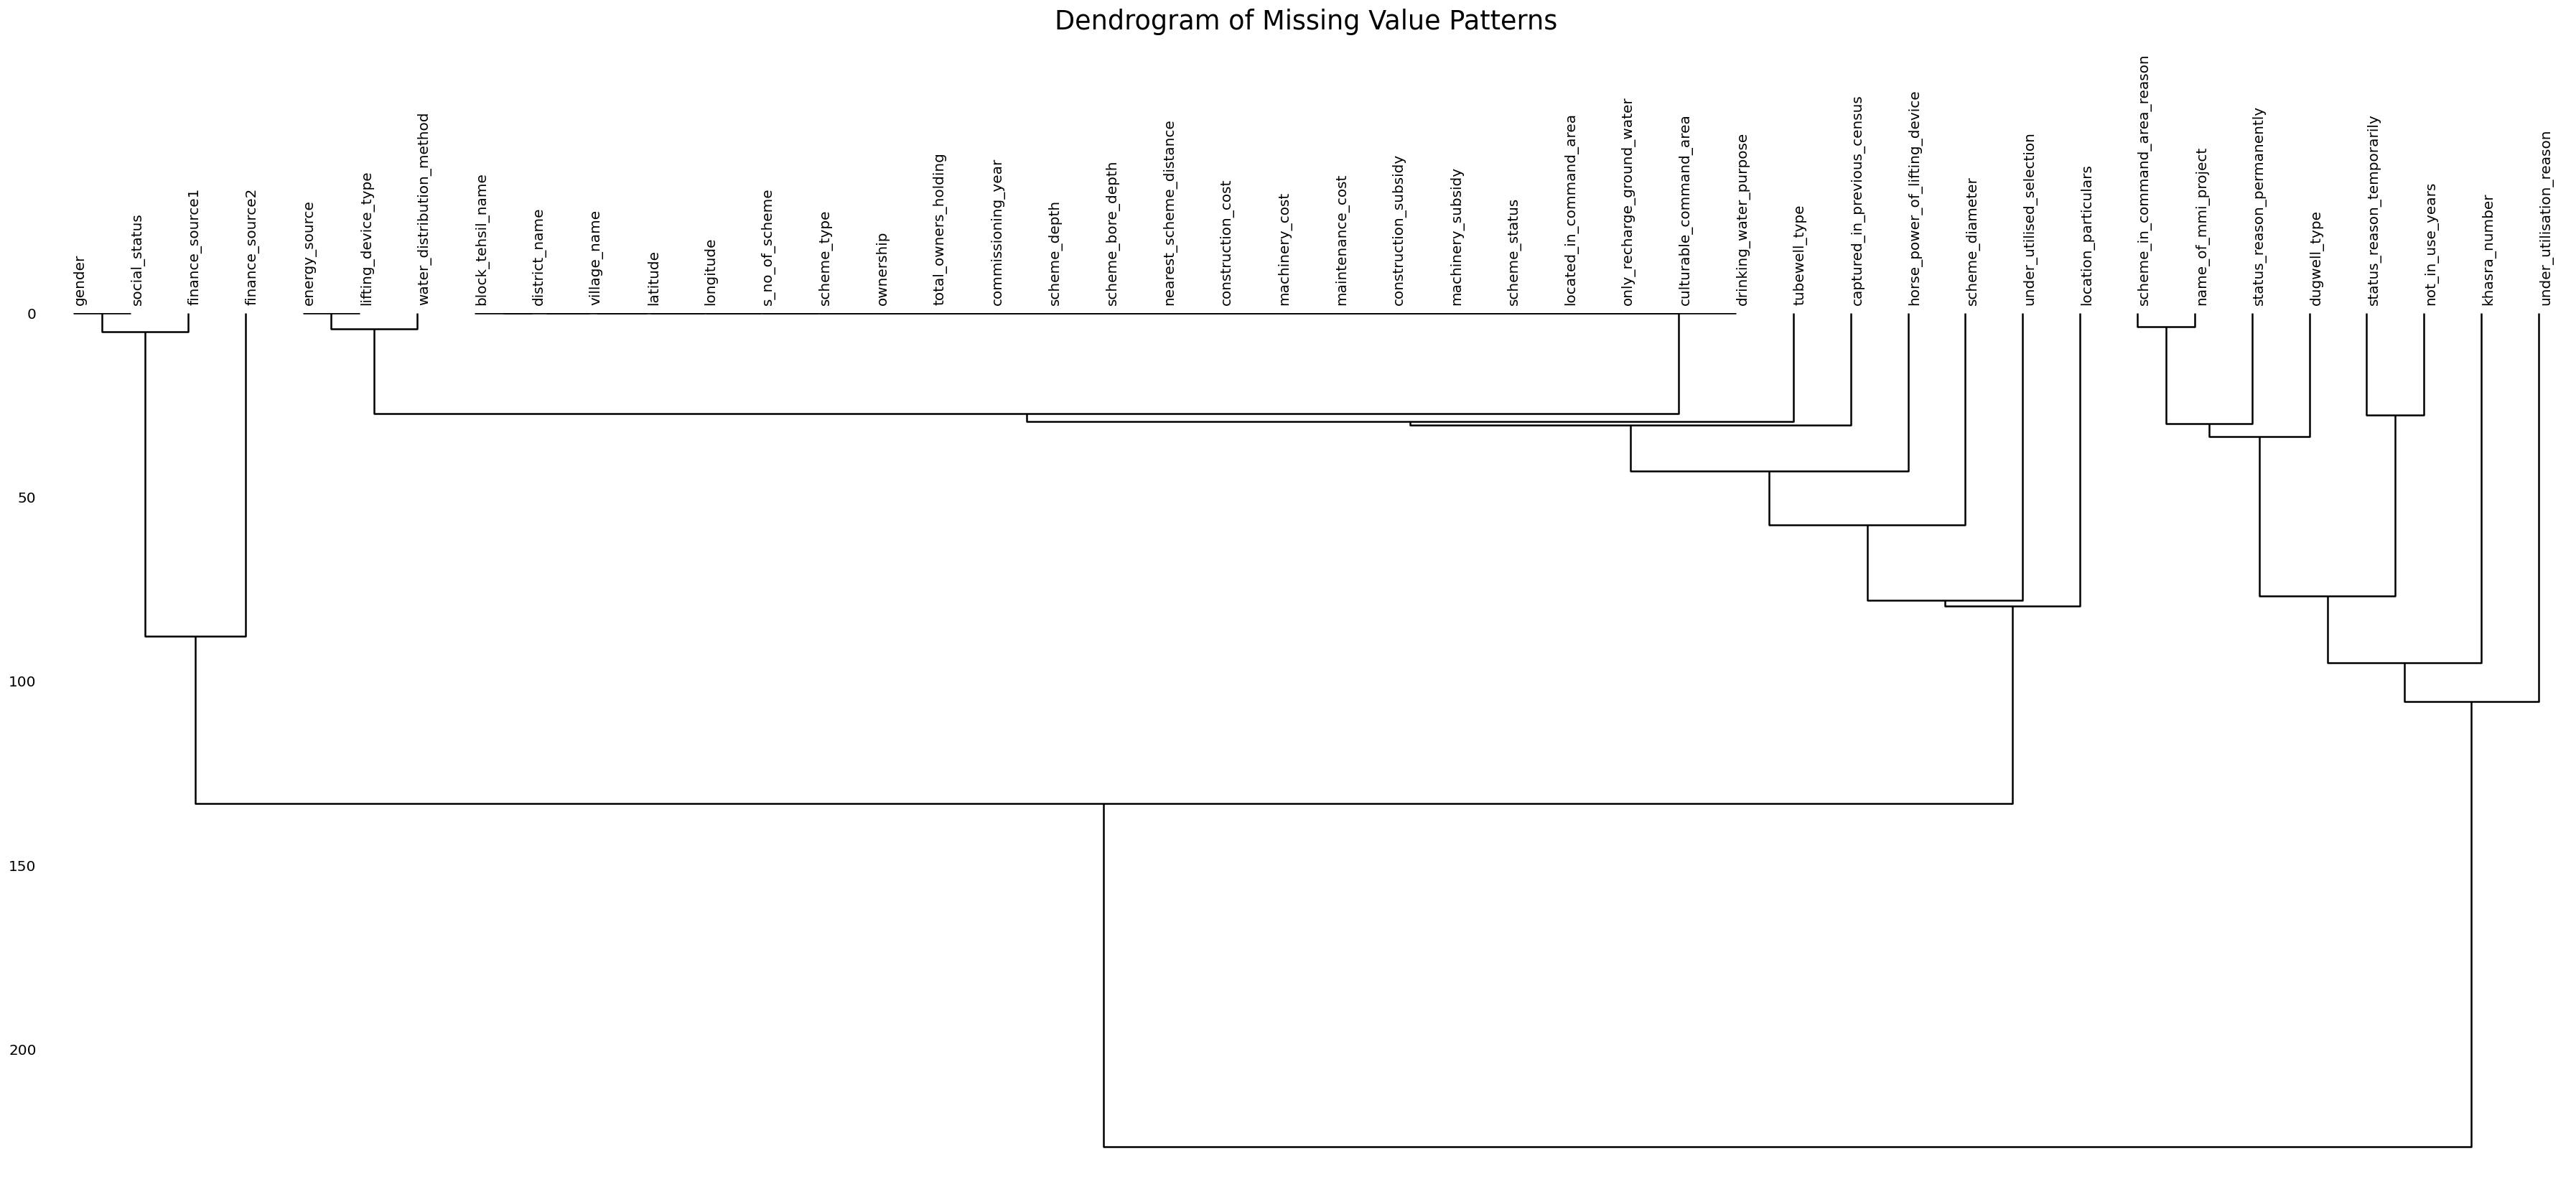

In [102]:
plt.figure(figsize=(30, 14), dpi=150)

msno.dendrogram(
    df,
    figsize=(30, 14),
    fontsize=14
)

plt.title('Dendrogram of Missing Value Patterns', fontsize=22, pad=20)
plt.xticks(rotation=90, fontsize=12)
plt.yticks(fontsize=12)
plt.tight_layout()
plt.show()

In [103]:
# Captured in previous sencus and well type are related
# Location and underutilization are related

## Misisng Value relation

In [104]:
row_missing_summary = pd.DataFrame({
    'Missing_Count': df.isnull().sum(axis=1),
    'Missing_Percentage': df.isnull().mean(axis=1) * 100
})

row_missing_summary = row_missing_summary.sort_values(
    'Missing_Percentage',
    ascending=False
)

row_missing_summary.head(10)

,Missing_Count,Missing_Percentage
27034,16,36.363636
56277,16,36.363636
27133,16,36.363636
56237,16,36.363636
56238,16,36.363636
56282,16,36.363636
27064,16,36.363636
27065,16,36.363636
27066,16,36.363636
56283,16,36.363636


In [105]:
from IPython.display import display

with pd.option_context(
    'display.max_columns', None,
    'display.max_rows', None,
    'display.max_colwidth', None,
    'display.width', None
):
    display(df.loc[row_missing_summary.head(10).index])

,district_name,block_tehsil_name,village_name,latitude,longitude,s_no_of_scheme,scheme_type,dugwell_type,tubewell_type,ownership,khasra_number,location_particulars,total_owners_holding,social_status,gender,commissioning_year,scheme_depth,scheme_diameter,scheme_bore_depth,nearest_scheme_distance,construction_cost,machinery_cost,maintenance_cost,finance_source1,finance_source2,construction_subsidy,machinery_subsidy,scheme_status,not_in_use_years,status_reason_temporarily,status_reason_permanently,water_distribution_method,lifting_device_type,energy_source,horse_power_of_lifting_device,located_in_command_area,name_of_mmi_project,scheme_in_command_area_reason,only_recharge_ground_water,culturable_command_area,under_utilised_selection,under_utilisation_reason,drinking_water_purpose,captured_in_previous_census
27034,Jorhat,Jorhat Central,Pakhimora Gaon,26.814142,94.295188,2,Tube well,NaN,Deep Tube well,Govt. Owned,NaN,Near lahdoigarh road,0.0,NaN,NaN,Up to 2018-2019,80.0,NaN,0.0,100.0,400000.0,50000.0,50000.0,NaN,NaN,40000.0,10000.0,Permanently Not in use,4.0,NaN,Due to other reasons,NaN,NaN,NaN,NaN,No,NaN,NaN,Yes,0.0,NaN,NaN,No,Yes
56277,Darrang,Dalgaon-Sialmari,Ruhinikhuti,26.528238,92.181080,1,Tube well,NaN,Medium Tube well,Govt. Owned,NaN,NaN,0.0,NaN,NaN,Up to 2018-2019,43.3,150.00,0.0,200.0,427200.0,25000.0,10000.0,NaN,NaN,0.0,0.0,Permanently Not in use,3.0,NaN,Destroyed beyond repair,NaN,NaN,NaN,NaN,No,NaN,NaN,No,4.0,NaN,NaN,No,No
27133,Barpeta,Sarukhetri,Josodar Pam,26.347406,91.170536,7,Tube well,NaN,Shallow Tube well,Others,NaN,NA,0.0,NaN,NaN,During 2019-2020,24.0,100.00,0.0,100.0,10000.0,25000.0,0.0,NaN,NaN,10000.0,10000.0,Permanently Not in use,3.0,NaN,Due to other reasons,NaN,NaN,NaN,NaN,No,NaN,NaN,No,2.0,NaN,NaN,No,NaN
56237,Darrang,Bechimari,Sarichabari,26.571509,92.168028,4,Tube well,NaN,Shallow Tube well,Govt. Owned,NaN,NaN,0.0,NaN,NaN,During 2019-2020,30.0,0.15,0.0,200.0,427200.0,427200.0,10000.0,NaN,NaN,427200.0,427200.0,Permanently Not in use,5.0,NaN,Destroyed beyond repair,NaN,NaN,NaN,NaN,No,NaN,NaN,No,4.0,NaN,NaN,No,No
56238,Darrang,Bechimari,Sarichabari,26.570742,92.165217,6,Tube well,NaN,Medium Tube well,Govt. Owned,NaN,NaN,0.0,NaN,NaN,During 2019-2020,43.3,0.15,0.0,200.0,427200.0,427200.0,10000.0,NaN,NaN,427200.0,427200.0,Permanently Not in use,5.0,NaN,Destroyed beyond repair,NaN,NaN,NaN,NaN,No,NaN,NaN,No,4.0,NaN,NaN,No,No
56282,Darrang,Dalgaon-Sialmari,Baruajhar 1/2,26.604455,92.130733,22,Tube well,NaN,Deep Tube well,Govt. Owned,NaN,NaN,0.0,NaN,NaN,During 2020-2021,80.0,250.00,0.0,200.0,3500000.0,2000000.0,5000.0,NaN,NaN,0.0,0.0,Permanently Not in use,5.0,NaN,Destroyed beyond repair,NaN,NaN,NaN,NaN,No,NaN,NaN,No,4.0,NaN,NaN,No,No
27064,Darrang,Dalgaon-Sialmari,Gadhaijhar,26.554078,92.178876,19,Tube well,NaN,Shallow Tube well,Others,NaN,NaN,0.0,NaN,NaN,During 2020-2021,20.0,150.00,0.0,200.0,30000.0,20000.0,5000.0,NaN,NaN,0.0,0.0,Permanently Not in use,3.0,NaN,Due to other reasons,NaN,NaN,NaN,NaN,No,NaN,NaN,No,4.0,NaN,NaN,No,No
27065,Darrang,Dalgaon-Sialmari,Gadhaijhar,26.554785,92.177337,20,Tube well,NaN,Shallow Tube well,Others,NaN,NaN,0.0,NaN,NaN,During 2021-2022,20.0,150.00,0.0,200.0,30000.0,20000.0,5000.0,NaN,NaN,0.0,0.0,Permanently Not in use,3.0,NaN,Due to other reasons,NaN,NaN,NaN,NaN,No,NaN,NaN,No,4.0,NaN,NaN,No,No
27066,Darrang,Dalgaon-Sialmari,Gadhaijhar,26.554463,92.176849,18,Tube well,NaN,Shallow Tube well,Others,NaN,NaN,0.0,NaN,NaN,During 2020-2021,20.0,150.00,0.0,200.0,3000.0,20000.0,5000.0,NaN,NaN,0.0,0.0,Permanently Not in use,3.0,NaN,Due to other reasons,NaN,NaN,NaN,NaN,No,NaN,NaN,No,4.0,NaN,NaN,No,No
56283,Darrang,Dalgaon-Sialmari,Baruajhar 1/2,26.609752,92.133375,23,Tube well,NaN,Deep Tube well,Govt. Owned,NaN,NaN,0.0,NaN,NaN,Up to 2018-2019,80.0,5.00,0.0,200.0,2500000.0,1500000.0,5000.0,NaN,NaN,30000.0,50000.0,Permanently Not in use,5.0,NaN,Dried up,NaN,NaN,NaN,NaN,No,NaN,NaN,No,4.0,NaN,NaN,No,No


In [106]:
# Govt. Owned tube wells have the highest missng values 

### Merging Columns

#### Merging tubewell_type and dugwell_type

In [107]:
# these are two seperate colums for well type they have MNAR relationship

In [108]:
df[df["tubewell_type"].isnull()].head(5)

,district_name,block_tehsil_name,village_name,latitude,longitude,s_no_of_scheme,scheme_type,dugwell_type,tubewell_type,ownership,khasra_number,location_particulars,total_owners_holding,social_status,gender,commissioning_year,scheme_depth,scheme_diameter,scheme_bore_depth,nearest_scheme_distance,construction_cost,machinery_cost,maintenance_cost,finance_source1,finance_source2,construction_subsidy,machinery_subsidy,scheme_status,not_in_use_years,status_reason_temporarily,status_reason_permanently,water_distribution_method,lifting_device_type,energy_source,horse_power_of_lifting_device,located_in_command_area,name_of_mmi_project,scheme_in_command_area_reason,only_recharge_ground_water,culturable_command_area,under_utilised_selection,under_utilisation_reason,drinking_water_purpose,captured_in_previous_census
144,Karbi Anglong,Langsomepi,Bagadal,26.240952,93.176784,4,Dug well,Dug well Pucca,NaN,Others,NaN,Near Ganeshthan LP School,0.0,NaN,NaN,Up to 2018-2019,15.0,1.0,0.0,120.0,30000.0,5000.0,1000.0,NaN,NaN,0.0,0.0,In-Use,NaN,NaN,NaN,Other,Manual/animal,Manual/animal,NaN,No,NaN,NaN,Yes,0.0,No,NaN,Yes,No
158,Marigaon,Mayang,Dahali Makaria,26.116028,92.336447,1,Dug well,Dug well Pucca,NaN,Panchayat Owned,NaN,near Namghar,0.0,NaN,NaN,Up to 2018-2019,20.0,1.0,0.0,20.0,100000.0,0.0,0.0,NaN,NaN,0.0,0.0,In-Use,NaN,NaN,NaN,Open Water Channel (lined / Pucca),Manual/animal,Manual/animal,NaN,No,NaN,NaN,Yes,0.0,No,NaN,Yes,No
358,Karbi Anglong,Langsomepi,Bagadal,26.241964,93.173108,8,Dug well,Dug well Pucca,NaN,Others,NaN,Near Ganeshthan LP,0.0,NaN,NaN,Up to 2018-2019,14.0,1.0,0.0,100.0,25000.0,4000.0,2000.0,NaN,NaN,0.0,0.0,In-Use,NaN,NaN,NaN,Other,Manual/animal,Manual/animal,NaN,No,NaN,NaN,Yes,0.0,No,NaN,Yes,No
511,Karbi Anglong,Langsomepi,Bagadal,26.241572,93.173330,9,Dug well,Dug well Pucca,NaN,Others,NaN,Near Goneshthan LP School,0.0,NaN,NaN,Up to 2018-2019,10.0,1.0,0.0,100.0,20000.0,4000.0,1500.0,NaN,NaN,0.0,0.0,In-Use,NaN,NaN,NaN,Other,Manual/animal,Manual/animal,NaN,No,NaN,NaN,Yes,0.0,No,NaN,Yes,No
539,Karbi Anglong,Nilip,Chandra Teron,26.370818,93.792138,1,Dug well,Dug well Pucca,NaN,Others,NaN,near by allsein charch,0.0,NaN,NaN,Up to 2018-2019,15.0,1.5,0.0,500.0,140000.0,20000.0,0.0,NaN,NaN,0.0,0.0,In-Use,NaN,NaN,NaN,Other,Manual/animal,Manual/animal,NaN,No,NaN,NaN,No,1.0,No,NaN,Yes,Yes


In [109]:
df[df["dugwell_type"].isnull()].head(5)

,district_name,block_tehsil_name,village_name,latitude,longitude,s_no_of_scheme,scheme_type,dugwell_type,tubewell_type,ownership,khasra_number,location_particulars,total_owners_holding,social_status,gender,commissioning_year,scheme_depth,scheme_diameter,scheme_bore_depth,nearest_scheme_distance,construction_cost,machinery_cost,maintenance_cost,finance_source1,finance_source2,construction_subsidy,machinery_subsidy,scheme_status,not_in_use_years,status_reason_temporarily,status_reason_permanently,water_distribution_method,lifting_device_type,energy_source,horse_power_of_lifting_device,located_in_command_area,name_of_mmi_project,scheme_in_command_area_reason,only_recharge_ground_water,culturable_command_area,under_utilised_selection,under_utilisation_reason,drinking_water_purpose,captured_in_previous_census
0,Goalpara,Kuchdhowa,Siluk Pt-Ii,25.956992,90.799726,1,Tube well,NaN,Medium Tube well,Govt. Owned,NaN,NEAR BR STORE,0.0,NaN,NaN,Up to 2018-2019,45.0,150.0,0.0,20.0,600000.0,150000.0,0.0,NaN,NaN,0.0,0.0,Temporarily Not in use,1.0,Mechanical break down,NaN,Other,Others,Solar,3.0,No,NaN,NaN,No,4.0,NaN,NaN,No,No
1,Kokrajhar,Kokrajhar,Bhadiaguri,26.355332,90.233585,12,Tube well,NaN,Shallow Tube well,Govt. Owned,NaN,Behind house of Jabar Ali Akond,0.0,NaN,NaN,During 2021-2022,35.0,150.0,0.0,100.0,100000.0,50000.0,0.0,NaN,NaN,0.0,0.0,Temporarily Not in use,1.0,Less discharge of water,NaN,Open Water Channel (lined / Pucca),Submersible pump,Solar,5.0,No,NaN,NaN,No,1.0,NaN,NaN,No,No
2,Goalpara,Kuchdhowa,Patiarpara Pt-I,25.971319,90.917621,1,Tube well,NaN,Medium Tube well,Govt. Owned,NaN,PATHIARPARA PT 1,0.0,NaN,NaN,Up to 2018-2019,69.0,150.0,0.0,69.0,450000.0,150000.0,0.0,NaN,NaN,0.0,0.0,Temporarily Not in use,1.0,Lack of maintenance,NaN,Open Water Channel (unlined / Kutcha),Others,Electric,3.0,No,NaN,NaN,No,4.0,NaN,NaN,No,Yes
3,Dhubri,Nayeralga,Boalkamri Pt.Iii,26.210017,90.160672,4,Tube well,NaN,Shallow Tube well,Owned by individual farmer,NaN,NA,0.3,Others,Male,During 2019-2020,20.0,80.0,0.0,100.0,20000.0,2000.0,500.0,Own savings,NaN,0.0,0.0,In-Use,NaN,NaN,NaN,Open Water Channel (unlined / Kutcha),Turbine/Jet pump,Diesel,5.0,No,NaN,NaN,No,2.0,No,NaN,No,No
4,Dhubri,Nayeralga,Boalkamri Pt.Iii,26.208178,90.161543,7,Tube well,NaN,Shallow Tube well,Owned by individual farmer,NaN,NA,1.0,Others,Male,During 2022-2023,20.0,80.0,0.0,200.0,20000.0,2000.0,500.0,Own savings,NaN,0.0,0.0,In-Use,NaN,NaN,NaN,Open Water Channel (unlined / Kutcha),Turbine/Jet pump,Diesel,5.0,No,NaN,NaN,No,2.5,No,NaN,No,No


In [110]:
df['well_type'] = np.select(
    [
        df['dugwell_type'].notna(),
        df['tubewell_type'].notna()
    ],
    [
        'Dugwell: ' + df['dugwell_type'].fillna('').astype(str),
        'Tubewell: ' + df['tubewell_type'].fillna('').astype(str)
    ],
    default=pd.NA
)

df.drop(
    columns=['dugwell_type', 'tubewell_type'],
    inplace=True
)

#### Merging finance_source1 and finance_source2

In [111]:
df.shape

(57303, 43)

In [112]:
# Finance Source 1 and 2 can be merged

In [113]:
df['finance_source'] = (
    df[['finance_source1', 'finance_source2']]
    .apply(
        lambda row: ', '.join(
            dict.fromkeys(
                str(v).strip()
                for v in row
                if pd.notna(v) and str(v).strip()
            )
        ) or pd.NA,
        axis=1
    )
)

In [114]:
df['finance_source'] = df['finance_source'].fillna(df['ownership'])

In [115]:
df['finance_source'] = df['finance_source'].replace({
    'Govt. Owned': 'Government fund',
    'Government fund, Own savings': 'Government fund, Own savings',
    'Own savings, Government fund': 'Own savings, Government fund'
})
df['finance_source'] = df['finance_source'].apply(
    lambda x: ', '.join(sorted(part.strip() for part in x.split(', ')))
    if pd.notna(x) else x
)

In [116]:
df['finance_source'].value_counts(dropna=False)

finance_source
Others, Own savings              28579
Government fund                  10335
Own savings                       7793
Others                            3233
Owned by Group of farmers         3221
Government fund, Own savings      1433
Government fund, Others           1002
Money lender, Own savings          823
Money lender, Others               316
Bank loan, Own savings             244
Co-Operative Owned                 136
Panchayat Owned                     85
Bank loan, Others                   38
Bank loan, Government fund          26
Government fund, Money lender       16
Money lender                        13
Bank loan                            7
Bank loan, Money lender              3
Name: count, dtype: int64

# Treating Missing Values

## Deleting Columns

In [117]:
cols_to_drop = [
    "scheme_in_command_area_reason",
    "name_of_mmi_project",
    "status_reason_permanently",
    "status_reason_temporarily",
    "not_in_use_years",
    "khasra_number",
    "under_utilisation_reason",
    'finance_source1', 
    'finance_source2'
]

df[cols_to_drop].isnull().sum().to_frame("Missing_Count").assign(
    Missing_Percentage=lambda x: (
        x["Missing_Count"] / len(df) * 100
    ).round(2),
    Data_Type=df[cols_to_drop].dtypes.astype(str)
)

,Missing_Count,Missing_Percentage,Data_Type
scheme_in_command_area_reason,57157,99.75,object
name_of_mmi_project,57142,99.72,object
status_reason_permanently,56536,98.66,object
status_reason_temporarily,51961,90.68,object
not_in_use_years,51194,89.34,float64
khasra_number,49735,86.79,float64
under_utilisation_reason,48757,85.09,object
finance_source1,15969,27.87,object
finance_source2,23688,41.34,object


In [118]:
df.drop(columns=cols_to_drop, inplace=True) 

In [119]:
print("Dataset shape:", df.shape)

Dataset shape: (57303, 35)


## Inputing Missing values Catagorical

In [120]:
missing_summary = pd.DataFrame({
    'Data_Type': df.dtypes.astype(str),
    'Missing_Count': df.isnull().sum(),
    'Missing_Percentage': (df.isnull().mean() * 100).round(2)
})

missing_summary = (
    missing_summary[missing_summary['Missing_Count'] > 0]
    .sort_values('Missing_Percentage', ascending=False)
)

missing_summary

,Data_Type,Missing_Count,Missing_Percentage
social_status,object,15942,27.82
gender,object,15942,27.82
under_utilised_selection,object,6039,10.54
location_particulars,object,5983,10.44
scheme_diameter,float64,3154,5.50
horse_power_of_lifting_device,float64,1919,3.35
captured_in_previous_census,object,837,1.46
water_distribution_method,object,767,1.34
lifting_device_type,object,748,1.31
energy_source,object,748,1.31


In [121]:
numeric_cols = df.select_dtypes(include=['number']).columns.tolist()
categorical_cols = df.select_dtypes(include=['object', 'category', 'string']).columns.tolist()

### working on social_status

In [122]:
print(df['social_status'].value_counts(dropna=False))
print(
    (df['social_status'].value_counts(normalize=True, dropna=False) * 100)
    .round(2)
)
df['social_status'] = df['social_status'].fillna('Unknown')

social_status
Others             31977
NaN                15942
OBC                 4455
Scheduled-tribe     2975
Scheduled-caste     1954
Name: count, dtype: int64
social_status
Others             55.80
NaN                27.82
OBC                 7.77
Scheduled-tribe     5.19
Scheduled-caste     3.41
Name: proportion, dtype: float64


In [123]:
df.assign(
    social_status_unknown=df['social_status'].eq('Unknown')
).groupby('ownership', dropna=False)['social_status_unknown'].agg(
    ['count', 'sum', 'mean']
).assign(
    Unknown_Percentage=lambda x: (x['mean'] * 100).round(2)
).drop(columns='mean').rename(
    columns={
        'count': 'Total_Records',
        'sum': 'Unknown_Count'
    }
).sort_values(
    'Unknown_Percentage', ascending=False
)

,Total_Records,Unknown_Count,Unknown_Percentage
ownership,,,
Panchayat Owned,85,85,100.00
Owned by Group of farmers,3242,3220,99.32
Others,2582,2563,99.26
Govt. Owned,10014,9938,99.24
Co-Operative Owned,138,136,98.55
Owned by individual farmer,41242,0,0.00


In [124]:
df.loc[
    df['ownership'] != 'Owned by individual farmer',
    'social_status'
] = 'Not applicable'

In [125]:
df.assign(
    social_status_not_applicable=df['social_status'].eq('Not applicable')
).groupby('ownership', dropna=False)['social_status_not_applicable'].agg(
    ['count', 'sum', 'mean']
).assign(
    Not_Applicable_Percentage=lambda x: (x['mean'] * 100).round(2)
).drop(columns='mean').rename(
    columns={
        'count': 'Total_Records',
        'sum': 'Not_Applicable_Count'
    }
).sort_values(
    'Not_Applicable_Percentage', ascending=False
)

,Total_Records,Not_Applicable_Count,Not_Applicable_Percentage
ownership,,,
Co-Operative Owned,138,138,100.0
Govt. Owned,10014,10014,100.0
Others,2582,2582,100.0
Owned by Group of farmers,3242,3242,100.0
Panchayat Owned,85,85,100.0
Owned by individual farmer,41242,0,0.0


In [126]:
# social status is missing for government owned and group of farmer owned wells MNAR relationship
"""
Owned by individual farmer: all 41,242 records have a recorded social status.
Govt. Owned: 9,938 of 10,014 records have missing social status.
Owned by Group of farmers: 3,220 of 3,242 are missing.
Panchayat Owned: all 85 are missing.
"""
print()

### working on gender column

In [127]:
print("Data type:", df['gender'].dtype)
print("Missing values:", df['gender'].isna().sum())
print("Missing percentage:", round(df['gender'].isna().mean() * 100, 2), "%")
print("\nGender distribution:")
print(df['gender'].value_counts(dropna=False))

print("\nGender distribution (%):")
print((df['gender'].value_counts(normalize=True, dropna=False) * 100).round(2))

Data type: object
Missing values: 15942
Missing percentage: 27.82 %

Gender distribution:
gender
Male           40784
NaN            15942
Female           565
Transgender       12
Name: count, dtype: int64

Gender distribution (%):
gender
Male           71.17
NaN            27.82
Female          0.99
Transgender     0.02
Name: proportion, dtype: float64


In [128]:
df.loc[
    df['ownership'] != 'Owned by individual farmer',
    'gender'
] = 'Not applicable'

In [129]:
df.assign(
    gender_not_applicable=df['gender'].eq('Not applicable')
).groupby('ownership', dropna=False)['gender_not_applicable'].agg(
    ['count', 'sum', 'mean']
).assign(
    Not_Applicable_Percentage=lambda x: (x['mean'] * 100).round(2)
).drop(columns='mean').rename(
    columns={
        'count': 'Total_Records',
        'sum': 'Not_Applicable_Count'
    }
).sort_values(
    'Not_Applicable_Percentage', ascending=False
)

,Total_Records,Not_Applicable_Count,Not_Applicable_Percentage
ownership,,,
Co-Operative Owned,138,138,100.0
Govt. Owned,10014,10014,100.0
Others,2582,2582,100.0
Owned by Group of farmers,3242,3242,100.0
Panchayat Owned,85,85,100.0
Owned by individual farmer,41242,0,0.0


In [130]:
# the wells owned by more than one person have missing value MNAR

In [131]:
df['gender'] = df['gender'].fillna('Unknown')

### working on under_utilised_selection

In [132]:
# Data type and missing values
print("Data type:", df['under_utilised_selection'].dtype)
print("Missing values:", df['under_utilised_selection'].isnull().sum())
print(
    "Missing percentage:",
    round(df['under_utilised_selection'].isnull().mean() * 100, 2), "%"
)

# Value distribution
print("\nUnder-utilised selection distribution:")
print(df['under_utilised_selection'].value_counts(dropna=False))

# Percentage distribution
print("\nUnder-utilised selection distribution (%):")
print(
    df['under_utilised_selection']
    .value_counts(dropna=False, normalize=True)
    .mul(100).round(2)
)

Data type: object
Missing values: 6039
Missing percentage: 10.54 %

Under-utilised selection distribution:
under_utilised_selection
No     42718
Yes     8546
NaN     6039
Name: count, dtype: int64

Under-utilised selection distribution (%):
under_utilised_selection
No     74.55
Yes    14.91
NaN    10.54
Name: proportion, dtype: float64


In [133]:
df.assign(
    selection_missing=df['under_utilised_selection'].isna()
).groupby('scheme_status', dropna=False)['selection_missing'].agg(
    ['count', 'sum', 'mean']
).assign(
    Missing_Percentage=lambda x: (x['mean'] * 100).round(2)
).drop(columns='mean').rename(
    columns={
        'count': 'Total_Records',
        'sum': 'Missing_Count'
    }
).sort_values(
    'Missing_Percentage', ascending=False
)

,Total_Records,Missing_Count,Missing_Percentage
scheme_status,,,
Temporarily Not in use,5342,5282,98.88
Permanently Not in use,767,757,98.70
In-Use,51194,0,0.00


In [134]:
pd.crosstab(
    df['scheme_status'],
    df['under_utilised_selection'],
    dropna=False
)

under_utilised_selection,No,Yes,NaN
scheme_status,,,
In-Use,42653,8541,0
Permanently Not in use,10,0,757
Temporarily Not in use,55,5,5282


In [135]:
df.loc[
    df['scheme_status'] == 'Permanently Not in use',
    'under_utilised_selection'
] = 'No'

In [136]:
df['under_utilised_selection'] = df['under_utilised_selection'].fillna('Unknown')

### Working on location_particulars

In [137]:
# Data type and missing values
print("Data type:", df['location_particulars'].dtype)
print("Missing values:", df['location_particulars'].isnull().sum())
print(
    "Missing percentage:",
    round(df['location_particulars'].isnull().mean() * 100, 2), "%"
)

# Value distribution
print("\nLocation particulars distribution:")
print(df['location_particulars'].value_counts(dropna=False))

# Percentage distribution
print("\nLocation particulars distribution (%):")
print(
    df['location_particulars']
    .value_counts(dropna=False, normalize=True)
    .mul(100).round(2)
)

Data type: object
Missing values: 5983
Missing percentage: 10.44 %

Location particulars distribution:
location_particulars
NaN                         5983
na                          2678
A                           1409
in filled                    736
near home                    524
                            ... 
near hen farm                  1
NASATARA  WATER SUPPLY         1
NEAR BR STORE                  1
BORBAM GAON                    1
no 37 kundaru LP School        1
Name: count, Length: 20022, dtype: int64

Location particulars distribution (%):
location_particulars
NaN                         10.44
na                           4.67
A                            2.46
in filled                    1.28
near home                    0.91
                            ...  
near hen farm                0.00
NASATARA  WATER SUPPLY       0.00
NEAR BR STORE                0.00
BORBAM GAON                  0.00
no 37 kundaru LP School      0.00
Name: proportion, Length: 20022, dtyp

In [138]:
df['location_particulars'] = df['location_particulars'].replace(
    r'(?i)^\s*(na|null|nan)\s*$',
    np.nan,
    regex=True
)
df['location_particulars'] = df['location_particulars'].replace(
    r'^\s*(a|0)\s*$',
    np.nan,
    regex=True
)

In [139]:
# Strip leading/trailing spaces and standardize casing
df['location_particulars'] = (
    df['location_particulars']
    .str.strip()
    .str.lower()
)

# Convert missing-value placeholders to NaN
df['location_particulars'] = df['location_particulars'].replace(
    r'^(na|null|nan|none|n/a|)$',
    np.nan,
    regex=True
)

# Display cleaned statistics
print("Data type:", df['location_particulars'].dtype)
print("Missing values:", df['location_particulars'].isnull().sum())
print(
    "Missing percentage:",
    round(df['location_particulars'].isnull().mean() * 100, 2), "%"
)

print("\nTop 20 values:")
print(df['location_particulars'].value_counts(dropna=False).head(20))

Data type: object
Missing values: 9965
Missing percentage: 17.39 %

Top 20 values:
location_particulars
NaN                       9965
a                         1412
near lp school             879
near road                  822
in filled                  776
near house                 713
near masjid                708
near paddy field           654
near home                  585
near pwd road              505
in paddy                   342
near jjm phe               333
near school                240
village                    238
near brahmaputra river     237
near mosjid                224
near own house             217
near jjm                   217
near brahmaputra           202
lp school                  200
Name: count, dtype: int64


In [140]:
df.drop(columns=['location_particulars'], inplace=True)

In [141]:
# location_particulars is not important for model training

### Working on captured_in_previous_census

In [142]:
import pandas as pd

pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)

result = pd.crosstab(
    [df['village_name'], df['commissioning_year']],
    df['captured_in_previous_census'].fillna('Unknown'),
    normalize='index'
).mul(100).round(2).sort_values(
    by='Unknown',
    ascending=False
)

result.head(20)

,captured_in_previous_census,No,Unknown,Yes
village_name,commissioning_year,,,
Besimari Pam,During 2021-2022,0.0,100.0,0.0
Agdia Pathar,During 2021-2022,0.0,100.0,0.0
Kabaribond Pt II,During 2021-2022,0.0,100.0,0.0
Deogharia Duwarah,During 2022-2023,0.0,100.0,0.0
Englong Parpan,During 2022-2023,0.0,100.0,0.0
Chakhowajar N.C.,During 2019-2020,0.0,100.0,0.0
Chandi Nagar Pt V,Up to 2018-2019,0.0,100.0,0.0
Agdia Pathar,During 2022-2023,0.0,100.0,0.0
Chandi Nagar Pt VI,During 2019-2020,0.0,100.0,0.0


In [143]:
# the data appears to be MNAR some villages have 100% missing data maybe beause the vilages are too remote 

In [144]:
result = pd.crosstab(
    [df['village_name'], df['commissioning_year']],
    df['captured_in_previous_census'].fillna('Unknown'),
    normalize='index'
).mul(100).round(2)

counts = pd.crosstab(
    [df['village_name'], df['commissioning_year']],
    df['captured_in_previous_census'].fillna('Unknown')
)

result['Total_Records'] = counts.sum(axis=1)

result.sort_values(
    by='Unknown',
    ascending=False
).head(30)

,captured_in_previous_census,No,Unknown,Yes,Total_Records
village_name,commissioning_year,,,,
Besimari Pam,During 2021-2022,0.0,100.0,0.0,5
Agdia Pathar,During 2021-2022,0.0,100.0,0.0,4
Kabaribond Pt II,During 2021-2022,0.0,100.0,0.0,2
Deogharia Duwarah,During 2022-2023,0.0,100.0,0.0,1
Englong Parpan,During 2022-2023,0.0,100.0,0.0,3
Chakhowajar N.C.,During 2019-2020,0.0,100.0,0.0,1
Chandi Nagar Pt V,Up to 2018-2019,0.0,100.0,0.0,1
Agdia Pathar,During 2022-2023,0.0,100.0,0.0,2
Chandi Nagar Pt VI,During 2019-2020,0.0,100.0,0.0,1


In [145]:
pd.crosstab(
    df['commissioning_year'],
    df['captured_in_previous_census'].fillna('Unknown'),
    normalize='index'
).mul(100).round(2)

captured_in_previous_census,No,Unknown,Yes
commissioning_year,,,
During 2019-2020,97.00,2.12,0.88
During 2020-2021,96.09,2.68,1.23
During 2021-2022,96.00,1.75,2.24
During 2022-2023,97.51,1.05,1.44
During 2023-2024,96.59,0.62,2.79
Up to 2018-2019,96.51,0.67,2.82


In [146]:
village_missing = pd.crosstab(
    df['village_name'],
    df['captured_in_previous_census'].fillna('Unknown'),
    normalize='index'
).mul(100).round(2)

village_missing['Total_Records'] = df.groupby(
    'village_name'
).size()

village_missing.sort_values(
    'Unknown',
    ascending=False
).head(30)

captured_in_previous_census,No,Unknown,Yes,Total_Records
village_name,,,,
Uttar Krishnapur Pt II,0.0,100.0,0.0,1
Tetelia Gaon,0.0,100.0,0.0,1
Upper Garumora,0.0,100.0,0.0,1
Uttar Burikamar,0.0,100.0,0.0,17
Rangia Gaon,0.0,100.0,0.0,17
Rupdiga,0.0,100.0,0.0,1
Sahan,0.0,100.0,0.0,1
Rawly,0.0,100.0,0.0,5
Ranthali,0.0,100.0,0.0,2


In [147]:
from scipy.stats import chi2_contingency

contingency = pd.crosstab(
    df['commissioning_year'],
    df['captured_in_previous_census'].fillna('Unknown')
)

chi2, p_value, dof, expected = chi2_contingency(contingency)

print(f"Chi-square statistic: {chi2:.3f}")
print(f"P-value: {p_value:.6g}")
print(f"Degrees of freedom: {dof}")

Chi-square statistic: 447.328
P-value: 7.76158e-90
Degrees of freedom: 10


In [148]:
import pandas as pd

pd.set_option('display.max_rows', 30)
pd.set_option('display.max_columns', None)

result = pd.crosstab(
    [df['latitude'], df['longitude']],
    df['captured_in_previous_census'].fillna('Unknown'),
    normalize='index'
).mul(100).round(2)

counts = pd.crosstab(
    [df['latitude'], df['longitude']],
    df['captured_in_previous_census'].fillna('Unknown')
)

result['Total_Records'] = counts.sum(axis=1)

result.sort_values(
    by='Unknown',
    ascending=False
).head(30)

,captured_in_previous_census,No,Unknown,Yes,Total_Records
latitude,longitude,,,,
26.122618,89.973773,0.0,100.0,0.0,1
25.987309,90.916389,0.0,100.0,0.0,1
26.274804,92.706934,0.0,100.0,0.0,1
26.074371,90.024418,0.0,100.0,0.0,1
24.619738,92.306433,0.0,100.0,0.0,1
24.619775,92.306255,0.0,100.0,0.0,1
26.244434,92.267073,0.0,100.0,0.0,1
26.123974,90.954565,0.0,100.0,0.0,1
24.622429,92.291806,0.0,100.0,0.0,1


In [149]:
df['captured_in_previous_census'] = df['captured_in_previous_census'].fillna('Unknown')

### Working on water_distribution_method

In [150]:
pd.crosstab(
    df['scheme_status'],
    df['water_distribution_method'],
    margins=True,
    dropna=False
)

water_distribution_method,Drip,Open Water Channel (lined / Pucca),Open Water Channel (unlined / Kutcha),Other,Sprinkler,Surface pipe,Under ground pipe,NaN,All
scheme_status,,,,,,,,,
In-Use,53,1837,17118,9823,57,20515,1791,0,51194
Permanently Not in use,0,0,0,0,0,0,0,767,767
Temporarily Not in use,7,404,1478,1009,3,2175,266,0,5342
All,60,2241,18596,10832,60,22690,2057,0,57303


In [151]:
# there is a MNAR relationship between these two columns the wells that are permanently not in use dont have a water distribution method

In [152]:
df['water_distribution_method'] = (
    df['water_distribution_method'].fillna('Not applicable')
)

### Wrking on energy_source, lifting_device_type

In [153]:
cols = ['energy_source', 'lifting_device_type']

for col in cols:
    print(f"\n--- {col} ---")
    print(df[col].value_counts(dropna=False))


--- energy_source ---
energy_source
Diesel           27323
Electric         18689
Solar             8678
Manual/animal     1116
NaN                748
Others             702
Wind Mills          25
Natural             22
Name: count, dtype: int64

--- lifting_device_type ---
lifting_device_type
Centrifugal Pump    36890
Submersible pump    11950
Others               4793
Turbine/Jet pump     1806
Manual/animal        1116
NaN                   748
Name: count, dtype: int64


In [154]:
for col in cols:
    print(f"\n--- {col} vs scheme_status ---")
    display(pd.crosstab(
        df['scheme_status'],
        df[col],
        margins=True,
        dropna=False
    ))


--- energy_source vs scheme_status ---


energy_source,Diesel,Electric,Manual/animal,Natural,Others,Solar,Wind Mills,NaN,All
scheme_status,,,,,,,,,
In-Use,25432,16246,1074,20,618,7780,24,0,51194
Permanently Not in use,8,8,1,1,0,1,0,748,767
Temporarily Not in use,1883,2435,41,1,84,897,1,0,5342
All,27323,18689,1116,22,702,8678,25,0,57303



--- lifting_device_type vs scheme_status ---


lifting_device_type,Centrifugal Pump,Manual/animal,Others,Submersible pump,Turbine/Jet pump,NaN,All
scheme_status,,,,,,,
In-Use,34603,1074,4451,9473,1593,0,51194
Permanently Not in use,9,1,1,8,0,748,767
Temporarily Not in use,2278,41,341,2469,213,0,5342
All,36890,1116,4793,11950,1806,0,57303


In [155]:
# MNAR with scheme status

In [156]:
cols = ['energy_source', 'lifting_device_type']

df[cols] = df[cols].fillna('Not applicable')

## Inputing Missing values Numerical

In [157]:
import pandas as pd
import numpy as np

# Analyze zero values in numerical columns
zero_summary = pd.DataFrame({
    "Zero_Count": (df[numeric_cols] == 0).sum(),
    "Zero_Percentage": (
        (df[numeric_cols] == 0).mean() * 100
    ).round(2)
})

# Sort by zero count
zero_summary = zero_summary.sort_values(
    by="Zero_Count",
    ascending=False
)

display(zero_summary)

,Zero_Count,Zero_Percentage
scheme_bore_depth,57028,99.52
construction_subsidy,47070,82.14
machinery_subsidy,46328,80.85
maintenance_cost,32568,56.83
total_owners_holding,16061,28.03
machinery_cost,2159,3.77
culturable_command_area,1825,3.18
construction_cost,173,0.30
scheme_diameter,64,0.11
longitude,0,0.00


### Dropping columns with too many missing values

In [158]:
cols_to_drop = [
    'scheme_bore_depth'
]

df.drop(columns=cols_to_drop, inplace=True)

### working on horse_power_of_lifting_device

In [159]:
mask = (
    df['horse_power_of_lifting_device'].isna()
    & df['lifting_device_type'].ne('Manual/animal')
    & df['lifting_device_type'].ne('Unknown')
    & df['scheme_status'].ne('Permanently Not in use')
)

display(
    df.loc[
        mask,
        [
            'lifting_device_type',
            'energy_source',
            'scheme_status',
            'scheme_type',
            'horse_power_of_lifting_device'
        ]
    ].value_counts(dropna=False).to_frame('Count')
)

Count
lifting_device_type energy_source scheme_status          scheme_type horse_power_of_lifting_device       
Others              Natural       In-Use                 Tube well   NaN                               20
                    Others        Temporarily Not in use Tube well   NaN                                6
Submersible pump    Others        In-Use                 Tube well   NaN                                5
Centrifugal Pump    Others        In-Use                 Tube well   NaN                                4
Others              Others        In-Use                 Tube well   NaN                                1
                    Natural       Temporarily Not in use Tube well   NaN                                1

In [160]:
hp_col = 'horse_power_of_lifting_device'

mask = (
    df[hp_col].isna()
    & df['lifting_device_type'].ne('Manual/animal')
    & df['lifting_device_type'].ne('Unknown')
    & df['scheme_status'].ne('Permanently Not in use')
)

display(
    df.loc[mask, [
        'lifting_device_type',
        'energy_source',
        'scheme_type',
        'scheme_status',
        hp_col
    ]]
)

,lifting_device_type,energy_source,scheme_type,scheme_status,horse_power_of_lifting_device
2705,Centrifugal Pump,Others,Tube well,In-Use,NaN
16860,Others,Natural,Tube well,In-Use,NaN
27859,Others,Others,Tube well,Temporarily Not in use,NaN
27860,Others,Others,Tube well,Temporarily Not in use,NaN
28068,Others,Others,Tube well,Temporarily Not in use,NaN
...,...,...,...,...,...
57298,Others,Natural,Tube well,In-Use,NaN
57299,Others,Natural,Tube well,In-Use,NaN
57300,Others,Natural,Tube well,In-Use,NaN
57301,Others,Natural,Tube well,In-Use,NaN


In [161]:
# missing value is related to energy_source for other and natural values are missing

In [162]:
# making horsepower 0 where it is not aplicable
df['horse_power_of_lifting_device'] = df['horse_power_of_lifting_device'].fillna(0)

### Working on scheme_diameter

In [163]:
zero_count = (df["scheme_diameter"] == 0).sum()
zero_percentage = (df["scheme_diameter"] == 0).mean() * 100

print("Zero Count:", zero_count)
print("Zero Percentage:", round(zero_percentage, 2), "%")

Zero Count: 64
Zero Percentage: 0.11 %


In [164]:
df["scheme_diameter"] = df["scheme_diameter"].fillna(0)

### Working on construction_cost

In [165]:
zero_count = (df["construction_cost"] == 0).sum()
zero_percentage = (df["construction_cost"] == 0).mean() * 100

print("Zero Count:", zero_count)
print("Zero Percentage:", round(zero_percentage, 2), "%")

Zero Count: 173
Zero Percentage: 0.3 %


In [166]:
import pandas as pd

# Identify zero construction costs
zero_flag = df["construction_cost"] == 0

# Analyze Scheme Type
print("\nScheme Type:")

scheme_results = []

for category in df["scheme_type"].dropna().unique():
    group = df[df["scheme_type"] == category]

    scheme_results.append({
        "Scheme Type": category,
        "Total Records": len(group),
        "Zero Cost Count": zero_flag.loc[group.index].sum(),
        "Zero Cost Percentage": round(
            zero_flag.loc[group.index].mean() * 100, 2
        )
    })

display(pd.DataFrame(scheme_results))


# Analyze Ownership
print("\nOwnership:")

ownership_results = []

for category in df["ownership"].dropna().unique():
    group = df[df["ownership"] == category]

    ownership_results.append({
        "Ownership": category,
        "Total Records": len(group),
        "Zero Cost Count": zero_flag.loc[group.index].sum(),
        "Zero Cost Percentage": round(
            zero_flag.loc[group.index].mean() * 100, 2
        )
    })

display(pd.DataFrame(ownership_results))


Scheme Type:


,Scheme Type,Total Records,Zero Cost Count,Zero Cost Percentage
0,Tube well,56494,158,0.28
1,Dug well,809,15,1.85



Ownership:


,Ownership,Total Records,Zero Cost Count,Zero Cost Percentage
0,Govt. Owned,10014,95,0.95
1,Owned by individual farmer,41242,40,0.10
2,Others,2582,20,0.77
3,Owned by Group of farmers,3242,17,0.52
4,Panchayat Owned,85,1,1.18
5,Co-Operative Owned,138,0,0.00


In [167]:
# Drop rows where construction_cost is zero
before = len(df)

df = df[df["construction_cost"] != 0].copy()

print("Rows Removed:", before - len(df))
print("Remaining Rows:", len(df))
print("Remaining Zero Values:", (df["construction_cost"] == 0).sum())

Rows Removed: 173
Remaining Rows: 57130
Remaining Zero Values: 0


### Working on scheme_diameter

In [168]:
# Diameter cannot be 0
df['scheme_diameter'] = df['scheme_diameter'].replace(0, np.nan)

In [169]:
display(
    df.groupby('scheme_type')['scheme_diameter'].agg(
        ['count', 'median', 'min', 'max']
    )
)

,count,median,min,max
scheme_type,,,,
Dug well,776,1.0,0.03,1000.0
Tube well,53163,80.0,0.01,35000.0


In [170]:
# Impute missing values using scheme-type-specific medians
df['scheme_diameter'] = df['scheme_diameter'].fillna(
    df.groupby('scheme_type')['scheme_diameter'].transform('median')
)

# Verify
print("Missing values:", df['scheme_diameter'].isnull().sum())
print("Zero diameter values:", (df['scheme_diameter'] == 0).sum())


Missing values: 0
Zero diameter values: 0


In [171]:
# These columns are derived from the construction cost, so drop them
df.drop(columns=[
    "machinery_cost",
    "maintenance_cost",
    "construction_subsidy",
    "machinery_subsidy"
], inplace=True)

# Saving dataset

In [172]:
df.to_csv("./data/03_Handling_Missing_Values.csv", index=False)